In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import json

In [2]:
df = pd.read_csv("hf://datasets/mstz/pima/pima/train.csv")

df.isna().sum()

number_of_pregnancies           0
plasma_glucose_concentration    0
diastolic_blood_pressure        0
triceps_thickness               0
serum_insulin                   0
bmi                             0
diabetes_pedigree               0
age                             0
has_diabetes                    0
dtype: int64

In [3]:
for c in df.columns:
    print(f"Column '{c}' has {df[c].nunique()} unique values")
    #print(df[c].unique())

Column 'number_of_pregnancies' has 17 unique values
Column 'plasma_glucose_concentration' has 136 unique values
Column 'diastolic_blood_pressure' has 47 unique values
Column 'triceps_thickness' has 51 unique values
Column 'serum_insulin' has 186 unique values
Column 'bmi' has 248 unique values
Column 'diabetes_pedigree' has 517 unique values
Column 'age' has 52 unique values
Column 'has_diabetes' has 2 unique values


In [4]:

X = df.drop('has_diabetes', axis=1)
y = df['has_diabetes']

# 5. Divisione in Training e Test Set (stratificata per mantenere le proporzioni del target)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()

# 3. Calcola media/varianza e scala SOLO sul Train Set
X_train = scaler.fit_transform(X_train)

# 4. Usa le stesse proporzioni trovate nel Train per scalare il Test Set
X_test = scaler.transform(X_test)


In [5]:
!pip install xgboost

"pip" non � riconosciuto come comando interno o esterno,
 un programma eseguibile o un file batch.


In [6]:
from xgboost import XGBClassifier
xg = XGBClassifier(objective='binary:logistic', 
                    max_depth = 6,
                    learning_rate = 1.0,
                    gamma = 0.0,
                    reg_lambda = 1,
                    tree_method='exact',
                    random_state=42
                   )

xg.fit(X_train, y_train)
y_pred = xg.predict(X_test)
y_pred_train = xg.predict(X_train)



In [7]:
print('Test Accuracy %s' % accuracy_score(y_test, y_pred))
print('Test F1-score %s' % f1_score(y_test, y_pred, average=None))
print(classification_report(y_test, y_pred))

Test Accuracy 0.7402597402597403
Test F1-score [0.8        0.62962963]
              precision    recall  f1-score   support

           0       0.80      0.80      0.80       100
           1       0.63      0.63      0.63        54

    accuracy                           0.74       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.74      0.74      0.74       154



In [8]:
from RuleTree.tree.TrepanClassifierOptimized import TrepanClassifierOptimized
from RuleTree.stumps.classification.MofNTrepanStumpClassifierOptimized import MofNTrepanStumpClassifierOptimized
trepan_clf = TrepanClassifierOptimized(estimator = xg,  base_stumps=MofNTrepanStumpClassifierOptimized(max_conditions=3),s_min=2500,  max_internal_nodes=9, random_state=42)
trepan_clf.fit(X_train, y_train)
y_pred_trepan = trepan_clf.predict(X_test)
print('Accuracy %s' % accuracy_score(y_test, y_pred_trepan))
print('F1-score %s' % f1_score(y_test, y_pred_trepan, average=None))
print(classification_report(y_test, y_pred_trepan))
fidelity = accuracy_score(y_pred, y_pred_trepan)
print("The fidelity respect to the oracle is %s" % fidelity)

Accuracy 0.7402597402597403
F1-score [0.80582524 0.60784314]
              precision    recall  f1-score   support

           0       0.78      0.83      0.81       100
           1       0.65      0.57      0.61        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.71       154
weighted avg       0.73      0.74      0.74       154

The fidelity respect to the oracle is 0.9090909090909091


In [9]:

trepan_clf.print_trepan_rules(feature_names=X.columns, scaler=scaler)


  REGOLE GLOBALI ESTRATTE DA TREPAN
  (VALORI RISCALATI ALLA SCALA ORIGINALE)
REGOLA 1 [Nodo ID: Rllll]:
  IF  (1-of-{ plasma_glucose_concentration <= 157.994, bmi <= 25.956 }}) AND 
      (1-of-{ plasma_glucose_concentration <= 164.396 }}) AND 
      (1-of-{ plasma_glucose_concentration <= 153.989 }}) AND 
      (1-of-{ bmi <= 27.402 }})
  THEN Predizione = 0
  [Fedeltà: 94.24%, Copertura: 22.64%]

REGOLA 2 [Nodo ID: Rlllrl]:
  IF  (1-of-{ plasma_glucose_concentration <= 157.994, bmi <= 25.956 }}) AND 
      (1-of-{ plasma_glucose_concentration <= 164.396 }}) AND 
      (1-of-{ plasma_glucose_concentration <= 153.989 }}) AND 
      (NOT (1-of-{ bmi <= 27.402 }})) AND 
      (1-of-{ plasma_glucose_concentration <= 94.009 }})
  THEN Predizione = 0
  [Fedeltà: 88.89%, Copertura: 13.19%]

REGOLA 3 [Nodo ID: Rlllrrlll]:
  IF  (1-of-{ plasma_glucose_concentration <= 157.994, bmi <= 25.956 }}) AND 
      (1-of-{ plasma_glucose_concentration <= 164.396 }}) AND 
      (1-of-{ plasma_glucose_c

In [10]:
from sklearn.tree import DecisionTreeClassifier

# Training del Decision Tree
dt_clf = DecisionTreeClassifier(random_state=42, max_leaf_nodes=10)
dt_clf.fit(X_train, y_pred_train)

# Predizioni
y_pred_dt = dt_clf.predict(X_test)

# Metriche
print('Accuracy %s' % accuracy_score(y_test, y_pred_dt))
print('F1-score %s' % f1_score(y_test, y_pred_dt, average=None))
print(classification_report(y_test, y_pred_dt))

fidelity = accuracy_score(y_pred, y_pred_dt)
print("The fidelity respect to the oracle is %s" % fidelity)

Accuracy 0.7922077922077922
F1-score [0.83838384 0.70909091]
              precision    recall  f1-score   support

           0       0.85      0.83      0.84       100
           1       0.70      0.72      0.71        54

    accuracy                           0.79       154
   macro avg       0.77      0.78      0.77       154
weighted avg       0.79      0.79      0.79       154

The fidelity respect to the oracle is 0.8831168831168831


In [11]:
import time

# Fissa un numero di nodi interpretabile
nodi = 6

smin_da_testare = [500,600,700,800,900,1000,1100,1200,1300,1400,1500,1600,1700,1800,1900,2000,2100,2200,2300,2400,2500,2600,2700,2800,2900,3000,3100,3200,3300,3400,3500,3600,3700,3800,3900,4000,4100,4200,4300,4400,4500,4600,4700,4800,4900,5000,5100,5200,5300,5400,5500,5600,5700,5800,5900,6000,6100,6200,6300,6400,6500,6600,6700,6800,6900,7000]
risultati_smin = []

for s in smin_da_testare:
    trepan_clf = TrepanClassifierOptimized(
        estimator=xg, 
        base_stumps=MofNTrepanStumpClassifierOptimized(max_conditions=3),
        s_min=s,
        max_internal_nodes=nodi, 
        min_real_samples=100,
        random_state=42
    )
    
    t0 = time.time()
    trepan_clf.fit(X_train, y_train)
    tempo = time.time() - t0
    
    y_pred_trepan = trepan_clf.predict(X_test)
    fid = accuracy_score(y_pred, y_pred_trepan) # Fedeltà all'oracolo
    
    risultati_smin.append({'S_min': s, 'Fidelity': fid, 'Time (s)': tempo})
    
    
print(max(risultati_smin, key=lambda x: x['Fidelity']))

{'S_min': 2500, 'Fidelity': 0.8636363636363636, 'Time (s)': 1.4496381282806396}


In [12]:
class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        if isinstance(obj, np.floating):
            return float(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return super(NumpyEncoder, self).default(obj)

In [13]:
import os
from RuleTree.tree.RuleTreeClassifier import RuleTreeClassifier
from RuleTree.stumps.classification.DecisionTreeStumpClassifier import DecisionTreeStumpClassifier


from RuleTree.utils.memory_utils import count_tree_structure

RESULTS_FILE = "risultati_pima.json"

if os.path.exists(RESULTS_FILE):
    try:
        with open(RESULTS_FILE) as f:
            results = json.load(f)
        print(f"Caricati {len(results)} risultati.")
    except json.JSONDecodeError:
        print("Il file JSON precedente era corrotto. Riparto da zero.")
        results = []
else:
    results = []

dati_grafici = []

nodi_da_testare = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30]

for nodi in nodi_da_testare:
    print(f"\n--- Addestramento con nodi interni max: {nodi} ---")
    
    # ==========================================
    # 1. BASELINE: CART (Surrogato Globale)
    # ==========================================
    # CART usa max_leaf_nodes, che equivale approssimativamente a nodi interni + 1
    dt_clf = DecisionTreeClassifier(random_state=42, max_leaf_nodes=nodi+1)
    
    t0 = time.time()
    dt_clf.fit(X_train, y_pred_train) # Fit sulle etichette dell'oracolo
    t_dt = time.time() - t0
    
    y_pred_dt_test = dt_clf.predict(X_test)
    acc_dt = accuracy_score(y_test, y_pred_dt_test)
    fid_dt = accuracy_score(y_pred, y_pred_dt_test)

    bal_acc_dt = balanced_accuracy_score(y_test, y_pred_dt_test)
    f1_macro_dt = f1_score(y_test, y_pred_dt_test, average='macro')
    
    results.append({
        "max_internal_nodes": int(nodi),
        "name": "CART",
        "accuracy": float(acc_dt),
        "fidelity": float(fid_dt),
        "balanced_accuracy": float(bal_acc_dt),
        "f1_macro": float(f1_macro_dt),
        "n_stumps": int(dt_clf.tree_.node_count - dt_clf.tree_.n_leaves), # Nodi interni Scikit-Learn
        "n_leaves": int(dt_clf.tree_.n_leaves),
        "n_rules_copies": 0, # CART non ha regole m-of-n
        "time_s": float(t_dt)
    })
    
    # ==========================================
    # 2. PROPOSTA: Trepan Optimized
    # ==========================================
    trepan_clf = TrepanClassifierOptimized(
        estimator=xg, 
        base_stumps=MofNTrepanStumpClassifierOptimized(max_conditions=3),
        s_min=2500,
        min_real_samples=100,
        max_internal_nodes=nodi, 
        random_state=42,
    )
    
    t0 = time.time()
    trepan_clf.fit(X_train, y_train)
    t_trepan = time.time() - t0
    
    y_pred_trepan_test = trepan_clf.predict(X_test)
    acc_trepan = accuracy_score(y_test, y_pred_trepan_test)
    fid_trepan = accuracy_score(y_pred, y_pred_trepan_test)

    # Nuove metriche di bilanciamento (calcolate sui dati reali y_test)
    bal_acc_trepan = balanced_accuracy_score(y_test, y_pred_trepan_test)
    f1_macro_trepan = f1_score(y_test, y_pred_trepan_test, average='macro')
        
    
    struct = count_tree_structure(trepan_clf.root)
    
    results.append({
        "max_internal_nodes": int(nodi),
        "name": "Trepan Opt",
        "accuracy": float(acc_trepan),
        "fidelity": float(fid_trepan),
        "balanced_accuracy": float(bal_acc_trepan),
        "f1_macro": float(f1_macro_trepan),
        "n_stumps": int(struct['n_stumps']),
        "n_leaves": int(struct['n_leaves']),
        "n_rules_copies": int(struct['n_rules_copies']) / 2,
        "time_s": float(t_trepan)
    })

    # ==========================================
    # 3. RULETREE (Base / Originale)
    # ==========================================
    # Inizializzare il RuleTree con gli stessi parametri base per un confronto equo
    rt_clf = RuleTreeClassifier(
        max_leaf_nodes=nodi+1, 
        random_state=42,
        base_stumps=DecisionTreeStumpClassifier(max_depth=1),
        
    )
    
    t0 = time.time()
    rt_clf.fit(X_train, y_pred_train)
    t_rt = time.time() - t0
    
    y_pred_rt_test = rt_clf.predict(X_test)
    
    # Se RuleTree usa la stessa struttura a nodi di Trepan Opt, 
    # puoi usare count_tree_structure. Altrimenti adatta il conteggio.
    try:
        struct_rt = count_tree_structure(rt_clf.root)
        rt_stumps = struct_rt['n_stumps']
        rt_leaves = struct_rt['n_leaves']
        rt_rules = struct_rt.get('n_rules_copies', 0) / 2
    except AttributeError:
        # Fallback se la struttura del RuleTree base è diversa
        rt_stumps = nodi
        rt_leaves = nodi + 1
        rt_rules = 0


    acc_rt = accuracy_score(y_test, y_pred_rt_test)
    fid_rt = accuracy_score(y_pred, y_pred_rt_test)
    bal_acc_rt = balanced_accuracy_score(y_test, y_pred_rt_test)
    f1_macro_rt = f1_score(y_test, y_pred_rt_test, average='macro')

    results.append({
        "max_internal_nodes": int(nodi),
        "name": "RuleTree",
        "accuracy": float(acc_rt),
        "fidelity": float(fid_rt),
        "balanced_accuracy": float(bal_acc_rt),
        "f1_macro": float(f1_macro_rt),
        "n_stumps": int(rt_stumps),
        "n_leaves": int(rt_leaves),
        "n_rules_copies": float(rt_rules),
        "time_s": float(t_rt)
    })# 1. Salva i dati di CART

    dati_grafici.append({
        'Nodes': nodi,
        'Model': 'CART',
        'Acc': acc_dt,          # Sostituisci con i nomi esatti delle tue variabili
        'Bal_Acc': bal_acc_dt,
        'F1_Macro': f1_macro_dt,
        'Fidelity': fid_dt,
        'Time': t_dt
    })

    # 2. Salva i dati di RuleTree
    dati_grafici.append({
        'Nodes': nodi,
        'Model': 'RuleTree',
        'Acc': acc_rt,
        'Bal_Acc': bal_acc_rt,
        'F1_Macro': f1_macro_rt,
        'Fidelity': fid_rt,
        'Time': t_rt
    })

    # 3. Salva i dati di Trepan Opt
    dati_grafici.append({
        'Nodes': nodi,
        'Model': 'Trepan Opt',
        'Acc': acc_trepan,
        'Bal_Acc': bal_acc_trepan,
        'F1_Macro': f1_macro_trepan,
        'Fidelity': fid_trepan,
        'Time': t_trepan
    })





# Salva i risultati su JSON
with open(RESULTS_FILE, "w") as f:
    json.dump(results, f, indent=2, cls=NumpyEncoder)

print("\nEsperimento completato e JSON aggiornato con successo.")



--- Addestramento con nodi interni max: 1 ---

--- Addestramento con nodi interni max: 2 ---

--- Addestramento con nodi interni max: 3 ---

--- Addestramento con nodi interni max: 4 ---

--- Addestramento con nodi interni max: 5 ---

--- Addestramento con nodi interni max: 6 ---

--- Addestramento con nodi interni max: 7 ---

--- Addestramento con nodi interni max: 8 ---

--- Addestramento con nodi interni max: 9 ---

--- Addestramento con nodi interni max: 10 ---

--- Addestramento con nodi interni max: 11 ---

--- Addestramento con nodi interni max: 12 ---

--- Addestramento con nodi interni max: 13 ---

--- Addestramento con nodi interni max: 14 ---

--- Addestramento con nodi interni max: 15 ---

--- Addestramento con nodi interni max: 16 ---

--- Addestramento con nodi interni max: 17 ---

--- Addestramento con nodi interni max: 18 ---

--- Addestramento con nodi interni max: 19 ---

--- Addestramento con nodi interni max: 20 ---

--- Addestramento con nodi interni max: 21 ---



In [14]:

with open(RESULTS_FILE) as f:
    results_all = json.load(f)

df = pd.DataFrame(results_all)
# Teniamo solo l'ultima esecuzione per ogni combinazione
df = df.drop_duplicates(subset=["max_internal_nodes", "name"], keep="last").reset_index(drop=True)

# Selezioniamo solo le colonne rilevanti per struttura e performance
df = df[[
    "max_internal_nodes", "name",
    "accuracy", "balanced_accuracy", "f1_macro", "fidelity",
    "n_stumps", "n_leaves", "n_rules_copies", "time_s",
]]

df = df.sort_values(["max_internal_nodes", "name"], kind="stable").reset_index(drop=True)

def fmt(x, d=3):
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return "--"
    return f"{x:.{d}f}"

rows = []
prev = None
for _, r in df.iterrows():
    key = r["max_internal_nodes"]

    if prev is not None and prev != key:
        rows.append("\\midrule")

    rows.append(
        f"{int(key)} & {r['name']:<11} & "
        f"{fmt(r['accuracy'])} & {fmt(r['balanced_accuracy'])} & {fmt(r['f1_macro'])} & {fmt(r['fidelity'])} & "
        f"{int(r['n_stumps'])} & {int(r['n_leaves'])} & {int(r['n_rules_copies'])} & "
        f"{fmt(r['time_s'])} \\\\"
    )
    prev = key

body = "\n".join(rows)


latex = r"""\documentclass{article}
\usepackage[a4paper, left=1cm, right=2.5cm, top=2.5cm, bottom=2.5cm]{geometry}
\usepackage{booktabs}
\usepackage{makecell}
\usepackage{longtable} % Aggiunto per le tabelle multipagina

\begin{document}

\footnotesize
\setlength{\tabcolsep}{4pt}

\begin{longtable}{c l r r r r r r r r}
\caption{Confronto TREPAN Optimized, RuleTree base e CART per Pima Dataset al variare della complessità strutturale.}
\label{tab:pima_struttura} \\
\toprule
\makecell{Max Int.\\Nodes} & Model & Acc. & Bal. Acc. & F1 Macro & Fid. & Stumps & Leaves & m-of-n Rules & Time (s) \\
\midrule
\endfirsthead

\multicolumn{10}{c}%
{{\bfseries \tablename\ \thetable{} -- Continua dalla pagina precedente}} \\
\toprule
\makecell{Max Int.\\Nodes} & Model & Acc. & Bal. Acc. & F1 Macro & Fid. & Stumps & Leaves & m-of-n Rules & Time (s) \\
\midrule
\endhead

\midrule
\multicolumn{10}{r}{{Continua nella pagina successiva...}} \\
\endfoot

\bottomrule
\endlastfoot
""" + "\n" + body + "\n" + r"""\end{longtable}

\end{document}
"""

with open("tabella_struttura_pima.tex", "w") as f:
    f.write(latex)

print(latex)

\documentclass{article}
\usepackage[a4paper, left=1cm, right=2.5cm, top=2.5cm, bottom=2.5cm]{geometry}
\usepackage{booktabs}
\usepackage{makecell}
\usepackage{longtable} % Aggiunto per le tabelle multipagina

\begin{document}

\footnotesize
\setlength{\tabcolsep}{4pt}

\begin{longtable}{c l r r r r r r r r}
\caption{Confronto TREPAN Optimized, RuleTree base e CART per Pima Dataset al variare della complessità strutturale.}
\label{tab:pima_struttura} \\
\toprule
\makecell{Max Int.\\Nodes} & Model & Acc. & Bal. Acc. & F1 Macro & Fid. & Stumps & Leaves & m-of-n Rules & Time (s) \\
\midrule
\endfirsthead

\multicolumn{10}{c}%
{{\bfseries \tablename\ \thetable{} -- Continua dalla pagina precedente}} \\
\toprule
\makecell{Max Int.\\Nodes} & Model & Acc. & Bal. Acc. & F1 Macro & Fid. & Stumps & Leaves & m-of-n Rules & Time (s) \\
\midrule
\endhead

\midrule
\multicolumn{10}{r}{{Continua nella pagina successiva...}} \\
\endfoot

\bottomrule
\endlastfoot

1 & CART        & 0.695 & 0.599 & 0.593

F1 Macro dell'Oracolo: 0.715

Generazione grafici in corso...


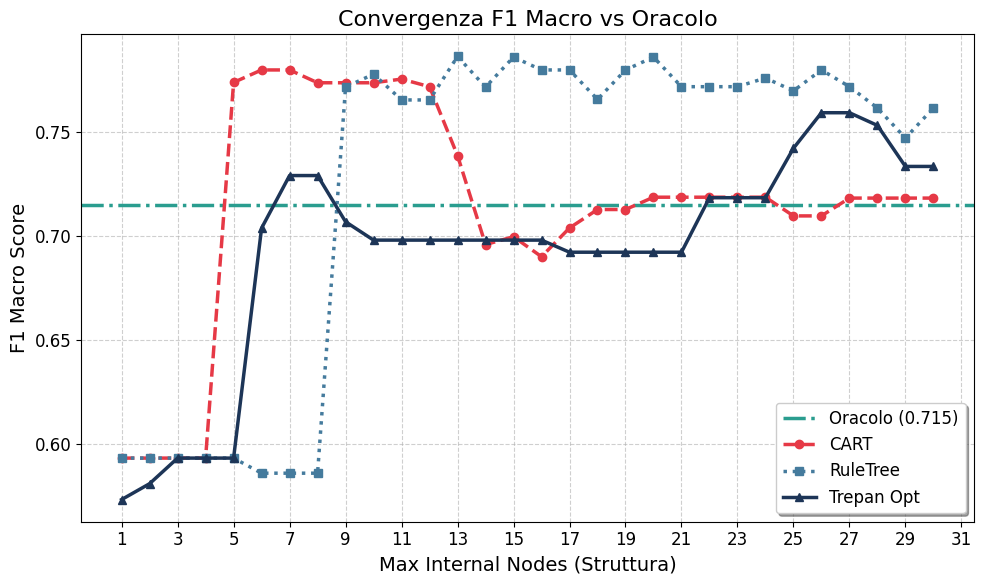

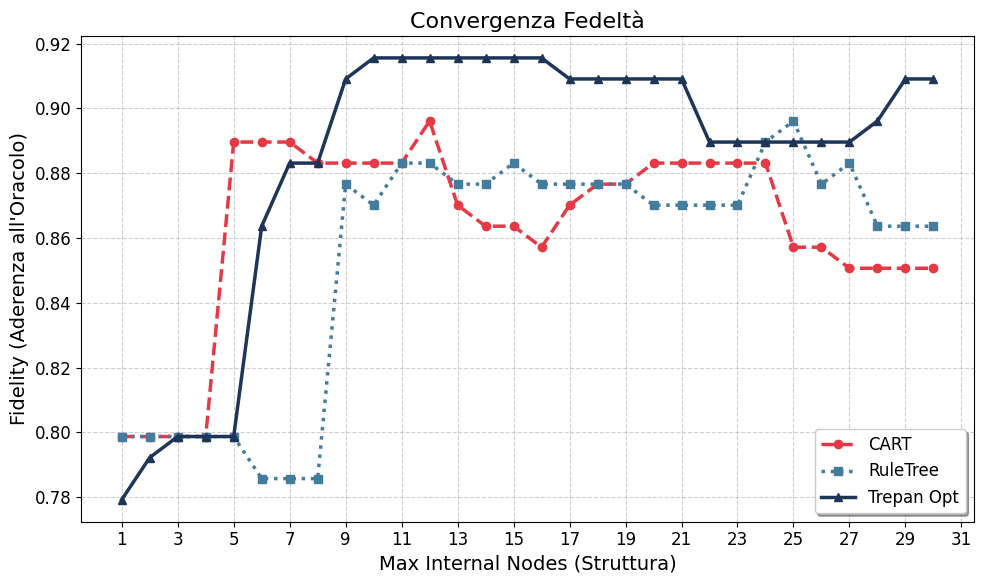

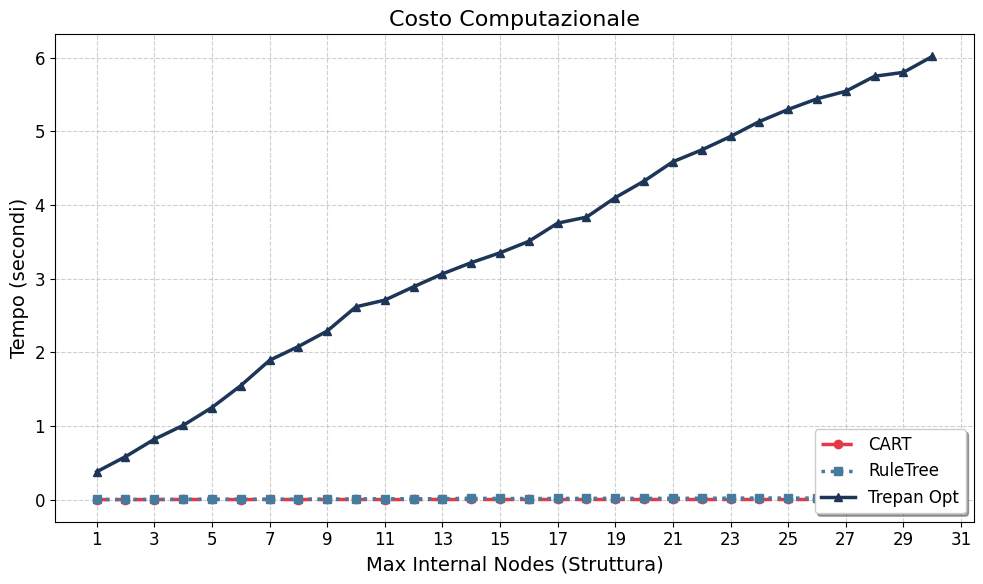

In [15]:


df = pd.DataFrame(results_all)
df = df.drop_duplicates(subset=["max_internal_nodes", "name"], keep="last").reset_index(drop=True)

df = df.rename(columns={
    'max_internal_nodes': 'Nodes',
    'name': 'Model',
    'accuracy': 'Acc',
    'balanced_accuracy': 'Bal_Acc',
    'f1_macro': 'F1_Macro',
    'fidelity': 'Fidelity',
    'time_s': 'Time'
})

# Calcolo esatto dell'F1 Macro dell'Oracolo (usa y_test e y_pred già presenti in memoria)
f1_oracle = f1_score(y_test, y_pred, average='macro')
print(f"F1 Macro dell'Oracolo: {f1_oracle:.3f}")

# Impostazioni di stile accademico per Matplotlib
plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'axes.titlesize': 16,
    'legend.fontsize': 12, 'lines.linewidth': 2.5, 'lines.markersize': 6
})

styles = {
    'CART': {'color': '#e63946', 'marker': 'o', 'linestyle': '--'},
    'RuleTree': {'color': '#457b9d', 'marker': 's', 'linestyle': ':'},
    'Trepan Opt': {'color': '#1d3557', 'marker': '^', 'linestyle': '-'}
}

def plot_metric_convergence(df, metric_col, ylabel, title, filename, oracle_val=None):
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Se viene passato il valore dell'Oracolo, traccia la linea orizzontale di riferimento
    if oracle_val is not None:
        ax.axhline(y=oracle_val, color='#2a9d8f', linestyle='-.', linewidth=2.5, 
                   label=f'Oracolo ({oracle_val:.3f})')

    for model_name in ['CART', 'RuleTree', 'Trepan Opt']:
        subset = df[df['Model'] == model_name]
        ax.plot(subset['Nodes'], subset[metric_col], 
                label=model_name, color=styles[model_name]['color'], 
                marker=styles[model_name]['marker'], linestyle=styles[model_name]['linestyle'])

    ax.set_xlabel('Max Internal Nodes (Struttura)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(np.arange(1, 32, 2))
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='lower right', frameon=True, shadow=True)
    
    plt.tight_layout()
    plt.savefig(f"{filename}.pdf", dpi=300, bbox_inches='tight')
    plt.savefig(f"{filename}.png", dpi=300, bbox_inches='tight')
    plt.show()

# Genera e salva i grafici (passando f1_oracle al primo grafico)
print("\nGenerazione grafici in corso...")
plot_metric_convergence(df, 'F1_Macro', 'F1 Macro Score', 'Convergenza F1 Macro vs Oracolo', 'pima_f1_macro_plot', oracle_val=f1_oracle)
plot_metric_convergence(df, 'Fidelity', 'Fidelity (Aderenza all\'Oracolo)', 'Convergenza Fedeltà', 'pima_fidelity_plot')
plot_metric_convergence(df, 'Time', 'Tempo (secondi)', 'Costo Computazionale', 'pima_time_plot')